# Sections 6 & 7 across 30 non-flaring holdout ARs — does seeding the 672-sample ensemble change its error bar?

Every bootstrap ensemble in this project shares one seed, so its member spread samples
**finite-sample** variance only: which 672 frames a replicate drew. The optimization path —
LoRA init draw, dropout, data order — is held fixed, and whatever that path contributes to
model uncertainty is invisible to the spread.

`672hr_stable_seed_diag` perturbs both at once. Arm *i* trains replicate *i* at `seed: i`, so
its across-member spread is the **total** of the two components rather than the first alone. If
the bootstrap spread were already capturing most of the model uncertainty, adding seed variation
should barely move it. If the spread grows, the published error bars are missing a component.

`view_seed_diag_168hrs_sections67.ipynb` asked this at the 168-sample budget. This is the
672-sample half, and it is the better-posed of the two: both arms here run the **same stabilized
recipe** (warmup 70 → cosine → `grad_clip_norm` 1.0), so LR schedule is not a confound the way
it is at 168 hr. What is left is the epoch budget — see the caveats below.

Same §6/§7 suite as `view_holdout_nonflaring30_sections67_672hr_stable.ipynb`, over the same 30
quiescent mid-sized ARs: boundary uncertainty, boundary error against truth, their ratio, the
variance decomposition, and calibration.

| | |
|---|---|
| **sweep** | `672hr_stable_seed_diag` — replicates 1–10 at seeds 1–10, stabilized recipe, mixed 4/5/6-epoch budget |
| **baseline** | `672hr_stable_generalized` — the *same* ten replicates at the implicit seed 0, uniform 6 epochs |
| **cohort** | the 30 non-flaring mid-sized holdout ARs, identical in both arms by construction |
| **epochs** | both arms at `epoch_select.py` best-generalized picks, **not** `best.pth` |

## Four things to hold on to before reading any number

**1. The contrast is seed AND epoch budget, and the budget bias is unevenly distributed.**
`NOTES` ("Under-training in `672hr_stable_seed_diag`") found the sweep was trained at
`max_epochs` 5 (boot01) and 4 (boot02–10) against the parent's uniform 6 — a config-regeneration
defect, not a design choice. Four members (boot06, boot07, boot09, boot10) were retrained at 6
epochs on 2026‑11‑03/04 and merged in place; the other six still sit at 4–5. So **4 of 10 pairs
are budget-matched and 6 are not**, and `epoch_select.py`'s `CONFOUND_NOTES` records why that is
worse for a paired test than a uniform offset would be. §2 reports the budget-matched subset
separately, which is the closest thing here to a clean seed read.

Read a **null** result as the stronger one: if perturbing seed *and* truncating the budget
together does not widen the error bar, seed alone certainly does not.

**2. Both arms are read at their best-generalized epoch.** Every other 672-sample inference run
in this project used `best.pth`, i.e. the valid/iou argmax, which `NOTES` rule 8 shows is
systematically the worst-calibrated checkpoint of its run. `epoch_select.py` mechanizes the eight
rules instead. This matters here for a specific reason: the baseline arm **had** to be
re-selected, because the sweep's table entry already holds generalized picks, and pairing the two
policies would have differenced seed, budget *and* the selection criterion at once. That is what
`672hr_stable_generalized` exists for. The consequence is that §7's calibration numbers are
**not** comparable to the published `672hr` / `672hr_stable` figures, including the best-IoU
`672hr_stable` cohort shown below for scale.

**3. The retrain did not improve the four members it touched.** At their chosen epochs boot07
fell 0.0143 and boot09 fell 0.0130 against their own archived 4-epoch counterparts, and all four
sit below their parent picks. All four also moved from `no-degradation` to `overfitting`. A
4-epoch cosine is a *complete* schedule annealed to `min_lr`, so its last checkpoint is fully
settled; 6 epochs spend two more at meaningful LR and buy IoU creep by degrading the probability
fit. "Budget-matched" is therefore not "better", and the subset split in §2 should be read as
*matched*, not as *good*.

**4. One sweep member has no good checkpoint.** `boot07`'s validation loss floors at epoch 1 and
is already +11.4 % above it by epoch 3, while its IoU is still climbing to epoch 5 — so its
selection window collapses to 3–3 and the pick lands **8.43 σ below its own peak IoU** via the
`none within noise of run max` fallback. Nothing in that run is both calibrated and
IoU-competitive. Expect it to be the sweep's visible outlier in the per-member tables.

## Setup

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import yaml
from scipy import stats

if "." not in sys.path:
    sys.path.insert(0, ".")
import ensemble_viz as ev      # palette + raster helpers, shared with the other viewers
import false_color as fcolor   # SURYA_PATCH_PX

ev.apply_rcparams()

BOOT = "/efs/bathomas/ar_seg_bootstrap"
SWEEP_ROOT = f"{BOOT}/672hr_stable_seed_diag_infer_holdout_nonflaring30"
# The seed-0 ensemble over the *same* 30 ARs at the *same* epoch policy: the ten 672hr_stable
# checkpoints re-selected by epoch_select.py, run under the 672hr_stable_generalized regime key.
# Read per frame rather than quoted, so every number below is a paired difference.
BASE_ROOT = f"{BOOT}/672hr_stable_gen_infer_holdout_nonflaring30"
# Context only, NOT comparisons. The 672hr_stable root is the same ten checkpoints at best.pth,
# so it is the price of the epoch policy rather than of the seed; the 168hr sweep is the same
# seed question one budget down.
REF_ROOTS = {
    "672hr_stable @best.pth": f"{BOOT}/672hr_stable_infer_holdout_nonflaring30",
    "168hrs_seed_diag": f"{BOOT}/168hrs_stable_seed_diag_infer_holdout_nonflaring30",
}
EPOCH_CSV = f"{BOOT}/672hr_stable_seed_diag_epoch_selection.csv"
CATALOG = "./assets/surya-bench-ar-segmentation/holdout_ar_nonflaring_30_from_test.csv"
SCALERS_PATH = "./assets/scalers.yaml"

# The four sweep members retrained to the parent's 6 epochs on 2026-11-03/04. Their pairs are the
# only budget-matched ones; see caveat 1. Asserted against the selection CSV below rather than
# trusted.
BUDGET_MATCHED = ["boot06", "boot07", "boot09", "boot10"]

PATCH_PX = fcolor.SURYA_PATCH_PX
MIN_N = 1000                 # reliability floor, as in the single-frame notebook
TRAIN_TRUE_FRAC = 0.00643    # training-era validation positive fraction
CHANNEL = "aia94"

frames = pd.read_csv(os.path.join(SWEEP_ROOT, "metrics_frame.csv"))
members = pd.read_csv(os.path.join(SWEEP_ROOT, "metrics_member_frame.csv"))
bins = pd.read_csv(os.path.join(SWEEP_ROOT, "calibration_bins.csv"))
dhist = pd.read_csv(os.path.join(SWEEP_ROOT, "distance_hist.csv"))
base_frames = pd.read_csv(os.path.join(BASE_ROOT, "metrics_frame.csv"))
base_members = pd.read_csv(os.path.join(BASE_ROOT, "metrics_member_frame.csv"))
base_bins = pd.read_csv(os.path.join(BASE_ROOT, "calibration_bins.csv"))
base_dhist = pd.read_csv(os.path.join(BASE_ROOT, "distance_hist.csv"))
catalog = pd.read_csv(CATALOG)
epochs = pd.read_csv(EPOCH_CSV)
scalers = yaml.safe_load(open(SCALERS_PATH))
ref = {k: pd.read_csv(os.path.join(v, "metrics_frame.csv")) for k, v in REF_ROOTS.items()}

MEMBERS = sorted(members.member.unique())
N = len(MEMBERS)
NF = len(frames)

print(f"sweep    {NF} frames x {N} members = {len(members)} member-frame rows")
print(f"baseline {len(base_frames)} frames x {base_members.member.nunique()} members "
      f"= {len(base_members)} rows")

# Every downstream aggregate assumes a complete balanced design; a partial inference run would
# otherwise be averaged silently.
assert len(members) == NF * N, f"expected {NF * N} sweep member-frame rows, got {len(members)}"
assert len(base_members) == NF * N, f"baseline incomplete: {len(base_members)}"

for tag, f in [("sweep", frames), ("baseline", base_frames)]:
    bad = f[f.mean_check_abs_diff > 1e-3]
    empty = f[f.empty_boundary_members.fillna("").astype(str).str.strip().ne("")]
    print(f"{tag:9s} fp16 mean-check failures: {len(bad) if len(bad) else 'none'};  "
          f"frames where a member predicted nothing: {len(empty) if len(empty) else 'none'}")

# The pairing is verifiable, not asserted: ground-truth positive fraction is a property of the
# masks alone, so it MUST be bit-identical across the two runs.
pair = frames.merge(base_frames, on="harpnum", suffixes=("", "_old"))
assert len(pair) == NF, f"paired on {len(pair)} of {NF} ARs"
dtruth = (pair.truth_frac - pair.truth_frac_old).abs().max()
print(f"\npaired on {len(pair)}/{NF} ARs;  max |truth_frac difference| = {dtruth:.3e}  "
      f"({'identical, pairing is real' if dtruth == 0 else 'NOT IDENTICAL -- pairing broken'})")
assert dtruth == 0

sweep    30 frames x 10 members = 300 member-frame rows
baseline 30 frames x 10 members = 300 rows
sweep     fp16 mean-check failures: none;  frames where a member predicted nothing: none
baseline  fp16 mean-check failures: none;  frames where a member predicted nothing: none

paired on 30/30 ARs;  max |truth_frac difference| = 0.000e+00  (identical, pairing is real)


## 1. What was run, and at which epoch

The epoch is the one thing this comparison had to choose, so it is reported before any metric.
`epoch_select.py` applied `NOTES`' eight rules to each member's own curve: the **window** runs
from the last epoch that took new high ground in IoU by more than 2 jitter σ to the first
post-floor epoch whose validation loss is more than 10 % above its floor, and the pick is the
earliest epoch inside that window still within 2 σ of the run's peak IoU.

**Read the `n ep` column first.** The baseline is a uniform 6 everywhere; the sweep reads
5, 4, 4, 4, 4, 6, 6, 4, 6, 6. That column *is* the confound of caveat 1, and it is why epoch
indices are not comparable across the sweep's members and per-member selection is mandatory
rather than merely tidy.

Then `def/s` — the pick's IoU deficit from its own run's peak, in jitter σ. Everything is under
3 except the sweep's `boot07` at **8.43**, the window collapse of caveat 4.

In [2]:
sel = epochs.copy()
sel["arm"] = sel.arm.map({"672hr_stable_seed_diag": "sweep", "672hr_stable": "baseline"})
assert sel.arm.notna().all(), "unexpected arm name in the selection CSV"
view = sel[["arm", "member", "replicate", "n_epochs", "window_lo", "window_hi", "chosen_epoch",
            "best_iou_epoch", "loss_floor_epoch", "sigma", "iou_chosen", "iou_best",
            "iou_deficit_sigma", "vloss_excess_pct", "regime"]].copy()
view.columns = ["arm", "member", "replicate", "n ep", "w_lo", "w_hi", "pick", "bIoU", "flr",
                "sigma", "IoU", "IoU max", "def/s", "+%flr", "diagnosis"]
for arm in ("sweep", "baseline"):
    print(f"--- {arm}")
    print(view[view.arm == arm].drop(columns="arm").to_string(
        index=False, float_format=lambda x: f"{x:.4f}"))
    print()

for arm in ("sweep", "baseline"):
    a = sel[sel.arm == arm]
    print(f"{arm:9s} validation IoU at the chosen epoch  "
          f"{a.iou_chosen.mean():.4f} +/- {a.iou_chosen.std(ddof=1):.4f}   "
          f"[{a.iou_chosen.min():.4f}, {a.iou_chosen.max():.4f}]")
    print(f"{'':9s} best.pth would sit "
          f"{(a.best_iou_epoch - a.loss_floor_epoch).mean():.1f} epochs past the loss floor, "
          f"costing {a.vloss_excess_at_best_iou_pct.mean():+.1f}% validation loss")
    print(f"{'':9s} median jitter sigma {a.sigma.median():.4f}   "
          f"max {a.sigma.max():.4f} ({a.loc[a.sigma.idxmax(), 'member']})")
    print(f"{'':9s} epoch budgets {sorted(a.n_epochs.tolist())}")

# The epoch each run actually used is recorded in the prob_*.nc attrs, so the caches can confirm
# the tables rather than being trusted to match them.
for tag, m, arm in [("sweep", members, "sweep"), ("baseline", base_members, "baseline")]:
    got = m.groupby("member").epoch.first().to_dict()
    want = dict(zip(sel[sel.arm == arm].member, sel[sel.arm == arm].chosen_epoch))
    print(f"\n{tag:9s} epochs in the cache match the selection table: {got == want}")
    assert got == want, f"{tag}: cache {got} != table {want}"

# BUDGET_MATCHED is a claim about the data, so check it against the CSV instead of trusting it.
sw_eps = sel[sel.arm == "sweep"].set_index("member").n_epochs
bs_eps = sel[sel.arm == "baseline"].set_index("member").n_epochs
derived = sorted(sw_eps.index[sw_eps.values == bs_eps[sw_eps.index].values])
print(f"\nbudget-matched members, derived from the CSV: {derived}")
assert derived == sorted(BUDGET_MATCHED), f"{derived} != {sorted(BUDGET_MATCHED)}"
print(f"  {len(derived)}/{N} pairs budget-matched at 6 epochs;  "
      f"{N - len(derived)}/{N} short by "
      f"{sorted(set((bs_eps[m] - sw_eps[m]) for m in sw_eps.index if m not in derived))} epoch(s)")

--- sweep
member         replicate  n ep  w_lo  w_hi  pick  bIoU  flr  sigma    IoU  IoU max  def/s   +%flr      diagnosis
boot01 train_boot001.csv     5     2     3     3     4    1 0.0027 0.5942   0.5963 0.7671 16.9138    overfitting
boot02 train_boot002.csv     4     2     3     2     3    1 0.0048 0.5833   0.5916 1.7392  4.2296    overfitting
boot03 train_boot003.csv     4     1     3     1     3    1 0.0053 0.6396   0.6467 1.3364  0.0000    overfitting
boot04 train_boot004.csv     4     1     3     1     2    2 0.0093 0.6263   0.6389 1.3542  3.2306 no-degradation
boot05 train_boot005.csv     4     2     3     2     3    2 0.0110 0.6469   0.6480 0.1025  0.0000 no-degradation
boot06 train_boot006.csv     6     5     5     5     5    3 0.0032 0.6084   0.6084 0.0000 12.8015    overfitting
boot07 train_boot007.csv     6     3     3     3     5    1 0.0021 0.6470   0.6644 8.4307 11.3600    overfitting
boot08 train_boot008.csv     4     2     3     2     3    3 0.0168 0.5830   0.6004 1.0

### The cohort

The column that matters most is **truth AR fraction**: these 30 ARs are the mid-sized quiescent
control, and §6's absolute scale depends on how much AR is actually in each frame.

In [3]:
cohort = frames.merge(
    catalog[["harpnum", "area_km2_million", "n_flares", "max_goes_class", "n_euv_events"]],
    on="harpnum", how="left",
).sort_values("truth_frac", ascending=False)

tbl = cohort[["harpnum", "frame", "area_km2_million", "n_flares", "n_euv_events", "truth_frac",
              "truth_density_vs_train", "soft_iou", "boundary_assd_px",
              "boundary_error_assd_px", "boundary_error_over_uncertainty", "brier", "bias"]]
tbl.columns = ["HARP", "frame", "area Mkm2", "fl", "EUV", "truth frac", "x train", "IoU",
               "UNC px", "ERR px", "ratio", "Brier", "bias"]
print(tbl.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\ntruth AR fraction: mean {frames.truth_frac.mean():.5f}  "
      f"median {frames.truth_frac.median():.5f}  "
      f"[{frames.truth_frac.min():.5f}, {frames.truth_frac.max():.5f}]  "
      f"= {frames.truth_density_vs_train.median():.2f}x the training-era rate "
      f"({TRAIN_TRUE_FRAC:.5f}) at the median")

 HARP         frame  area Mkm2  fl  EUV  truth frac  x train    IoU   UNC px   ERR px   ratio  Brier    bias
11510 20240713_1700 16170.0000   0    2      0.0375   5.8311 0.7527  11.0731  44.3299  4.0034 0.1105  0.0150
10434 20231127_0400 10889.0000   0    4      0.0344   5.3545 0.7615   6.4001  14.3405  2.2407 0.1171 -0.0288
11726 20240819_1900 11126.0000   0    6      0.0338   5.2623 0.8188   8.2281   7.4667  0.9075 0.0873 -0.0520
11555 20240719_1500 16004.0000   0    8      0.0330   5.1342 0.7744   6.7400   8.7008  1.2909 0.1092 -0.0050
11309 20240602_1400 11052.0000   0    4      0.0326   5.0657 0.8196   5.8201   8.3975  1.4428 0.0820 -0.0548
10515 20231220_1700 14163.0000   0    2      0.0292   4.5353 0.8017  10.0640  14.5274  1.4435 0.0954 -0.0114
11553 20240720_1800 18823.0000   0    2      0.0291   4.5208 0.7401   7.9481  16.9495  2.1325 0.1270  0.0461
10641 20240114_2200 13540.0000   0    1      0.0262   4.0671 0.6579  10.7843  29.9972  2.7816 0.1417  0.0054
12009 20241008_1300

## 2. §6 — how well located is the boundary, and does seeding widen it?

Three numbers carry this section:

- **UNC** — mean ASSD of the ten members' own $p_m = 0.5$ boundaries about the ensemble-mean
  boundary. What the ensemble thinks it knows.
- **ERR** — the same measurement against the ground-truth mask. How wrong it is.
- **ratio** — ERR / UNC. **1.0 would mean the spread is an honest error bar.**

Reported as mean ± *between-frame* sd. Two poolings of the ratio answer different questions: the
mean of 30 per-frame ratios weights every AR equally, while mean-ERR / mean-UNC is the
cohort-level ratio and is lower whenever one frame has a tiny UNC.

**The seed question is the UNC row.** If the optimization path carries variance the bootstrap
misses, the sweep's UNC should exceed the baseline's.

In [4]:
def describe(series, fmt="{:.3f}"):
    v = pd.to_numeric(series, errors="coerce").dropna()
    return (f"{fmt.format(v.mean())} +/- {fmt.format(v.std(ddof=1))}   "
            f"median {fmt.format(v.median())}   "
            f"[{fmt.format(v.min())}, {fmt.format(v.max())}]")


ROWS = [
    ("UNCERTAINTY  ASSD (px)", "boundary_assd_px", "{:.2f}"),
    ("  between-member sd (px)", "boundary_assd_sd_px", "{:.2f}"),
    ("  median (px)", "boundary_median_px", "{:.2f}"),
    ("  mean HD95 (px)", "boundary_hd95_px", "{:.1f}"),
    ("ERROR  ASSD (px)", "boundary_error_assd_px", "{:.2f}"),
    ("  median (px)", "boundary_error_median_px", "{:.2f}"),
    ("  HD95 (px)", "boundary_error_hd95_px", "{:.1f}"),
    ("ERROR / UNCERTAINTY", "boundary_error_over_uncertainty", "{:.2f}"),
    ("sigma_p on the boundary", "boundary_sigma_prob", "{:.4f}"),
    ("soft-mean IoU", "soft_iou", "{:.4f}"),
    ("member IoU sd", "member_iou_sd", "{:.4f}"),
]

for tag, f in [("SWEEP (seeds 1-10)", frames),
               ("BASELINE (seed 0, generalized)", base_frames)]:
    print(f"=== {tag}")
    print(f"{'':<34}{'mean +/- sd':>22}   median / range")
    print("-" * 78)
    for label, col, fmt in ROWS:
        print(f"{label:<34}{describe(f[col], fmt)}")
    print()

for tag, f in [("sweep", frames), ("baseline", base_frames)]:
    unc, err = f.boundary_assd_px.mean(), f.boundary_error_assd_px.mean()
    r = f.boundary_error_over_uncertainty
    print(f"{tag:9s} cohort-level mean-ERR/mean-UNC {err / unc:.2f}x   "
          f"mean of per-frame ratios {r.mean():.2f}x   median {r.median():.2f}x   "
          f"frames above 1.0: {int((r > 1).sum())}/{NF}   above 2.0: {int((r > 2).sum())}/{NF}")

print("\ncontext only, NOT a comparison (different epoch policy / different budget):")
for k, f in ref.items():
    print(f"  {k:24s} UNC {f.boundary_assd_px.mean():5.2f} px   "
          f"ERR {f.boundary_error_assd_px.mean():5.2f} px   "
          f"ratio {f.boundary_error_over_uncertainty.mean():.2f}x (mean of per-frame)")

=== SWEEP (seeds 1-10)
                                             mean +/- sd   median / range
------------------------------------------------------------------------------
UNCERTAINTY  ASSD (px)            14.45 +/- 21.05   median 10.21   [4.55, 120.93]
  between-member sd (px)          12.20 +/- 26.82   median 5.63   [1.66, 147.91]
  median (px)                     1.52 +/- 0.51   median 1.41   [1.00, 3.08]
  mean HD95 (px)                  110.2 +/- 193.5   median 59.6   [16.3, 982.1]
ERROR  ASSD (px)                  26.64 +/- 28.30   median 16.98   [7.47, 158.86]
  median (px)                     3.69 +/- 1.58   median 3.00   [2.24, 10.20]
  HD95 (px)                       171.3 +/- 199.5   median 106.3   [33.5, 1045.0]
ERROR / UNCERTAINTY               2.37 +/- 1.98   median 1.79   [0.25, 11.32]
sigma_p on the boundary           0.2305 +/- 0.0248   median 0.2327   [0.1798, 0.2895]
soft-mean IoU                     0.7301 +/- 0.0899   median 0.7535   [0.4583, 0.8518]
member IoU

### The paired test — the only one that can resolve this

The between-frame sd of the ratio is larger than any plausible shift between the two arms, so
unpaired cohort means resolve nothing. The 30 ARs are identical in both runs, so every row below
is a **Wilcoxon signed-rank test on the 30 per-AR differences**.

`n up` counts ARs where the sweep's value exceeds the baseline's. For UNC, "up" is the direction
that would mean seeding exposes variance the bootstrap missed.

In [5]:
def paired(col, fmt="{:.3f}", df=None):
    "One row: sweep mean, baseline mean, the difference, and Wilcoxon on the difference."
    p = pair if df is None else df
    new = pd.to_numeric(p[col], errors="coerce")
    old = pd.to_numeric(p[f"{col}_old"], errors="coerce")
    d = (new - old).dropna()
    _, pv = stats.wilcoxon(d)
    return (f"{fmt.format(new.mean()):>10}{fmt.format(old.mean()):>10}"
            f"{fmt.format(d.mean()):>11}{fmt.format(d.median()):>11}"
            f"{int((d > 0).sum()):>5}/{len(d)}{pv:>11.2e}"
            f"{'  *' if pv < 0.05 else ''}")


print(f"{'':<30}{'sweep':>10}{'seed 0':>10}{'mean d':>11}{'median d':>11}"
      f"{'n up':>8}{'Wilcoxon':>11}")
print("-" * 92)
for label, col, fmt in [
    ("UNCERTAINTY ASSD (px)", "boundary_assd_px", "{:.2f}"),
    ("member ASSD sd (px)", "boundary_assd_sd_px", "{:.2f}"),
    ("member HD95 (px)", "boundary_hd95_px", "{:.1f}"),
    ("ERROR ASSD (px)", "boundary_error_assd_px", "{:.2f}"),
    ("error HD95 (px)", "boundary_error_hd95_px", "{:.1f}"),
    ("ERROR / UNCERTAINTY", "boundary_error_over_uncertainty", "{:.2f}"),
    ("sigma_p on the boundary", "boundary_sigma_prob", "{:.4f}"),
    ("soft-mean IoU", "soft_iou", "{:.4f}"),
    ("soft precision", "soft_precision", "{:.4f}"),
    ("soft recall", "soft_recall", "{:.4f}"),
    ("member IoU sd", "member_iou_sd", "{:.4f}"),
    ("ensemble pred fraction", "soft_pred_frac", "{:.4f}"),
]:
    print(f"{label:<30}{paired(col, fmt)}")
print("\n* = p < 0.05")

d_unc = pair.boundary_assd_px - pair.boundary_assd_px_old
d_ratio = pair.boundary_error_over_uncertainty - pair.boundary_error_over_uncertainty_old
print(f"\n  ARs where seeding WIDENED the spread: {int((d_unc > 0).sum())}/{NF}   "
      f"relative change in UNC, median {100 * (d_unc / pair.boundary_assd_px_old).median():+.1f}%")
print(f"  ARs whose ratio improved (fell toward 1): {int((d_ratio < 0).sum())}/{NF}")
print(f"  ARs above 1.0 under both arms: "
      f"{int(((pair.boundary_error_over_uncertainty > 1) & (pair.boundary_error_over_uncertainty_old > 1)).sum())}/{NF}")
print(f"  worst single member-frame ASSD:  sweep {members.assd_px.max():.1f} px   "
      f"baseline {base_members.assd_px.max():.1f} px")
print(f"  member-frames above 100 px:      sweep {int((members.assd_px > 100).sum())}/{len(members)}   "
      f"baseline {int((base_members.assd_px > 100).sum())}/{len(base_members)}")

                                   sweep    seed 0     mean d   median d    n up   Wilcoxon
--------------------------------------------------------------------------------------------
UNCERTAINTY ASSD (px)              14.45     12.25       2.19       0.97   21/30   8.03e-02
member ASSD sd (px)                12.20     10.12       2.08       1.41   23/30   1.64e-02  *
member HD95 (px)                   110.2      81.6       28.5        6.7   22/30   1.75e-02  *
ERROR ASSD (px)                    26.64     25.26       1.38       0.45   18/30   2.89e-01
error HD95 (px)                    171.3     182.2      -10.8        2.1   18/30   5.10e-01
ERROR / UNCERTAINTY                 2.37      2.43      -0.06      -0.20   11/30   1.09e-01
sigma_p on the boundary           0.2305    0.2328    -0.0023    -0.0046   10/30   1.19e-01
soft-mean IoU                     0.7301    0.7296     0.0005     0.0008   16/30   1.00e+00
soft precision                    0.8543    0.8756    -0.0213    -0.0158 

### The budget-matched subset — the closest thing here to a clean seed read

Caveat 1's confound is not uniform: `boot06`, `boot07`, `boot09` and `boot10` of the sweep ran
the parent's full 6 epochs, the other six did not. The frame-level UNC above pools all ten
members, so it cannot be subset — but `metrics_member_frame.csv` carries each member's **own**
ASSD about its arm's ensemble-mean boundary, and those can be paired member-for-member on the
same replicate.

Two caveats on reading this, both of which cut against over-interpreting it:

- A member's ASSD is measured about *its own arm's* mean boundary, so the two columns are not
  measured against a common reference. This is a comparison of **dispersion about each arm's own
  centre**, not of absolute position.
- Budget-matched is not "good" (caveat 3). All four of these members regressed or tied at their
  chosen epochs relative to their own 4-epoch versions.

If the matched and short subsets shift in the same direction and by a similar amount, the budget
is not what is driving the frame-level result. If they disagree, the frame-level number is a
budget artifact and should be read as nothing else.

In [6]:
mm = members.merge(base_members, on=["frame", "member"], suffixes=("", "_old"))
assert len(mm) == NF * N, f"member-frame pairing incomplete: {len(mm)}"
mm["matched"] = mm.member.isin(BUDGET_MATCHED)

print(f"{'subset':<22}{'n':>6}{'sweep':>10}{'seed 0':>10}{'mean d':>11}{'median d':>11}"
      f"{'n up':>10}{'Wilcoxon':>11}")
print("-" * 90)
for label, sub in [("all 10 members", mm),
                   ("budget-matched (4)", mm[mm.matched]),
                   ("short budget (6)", mm[~mm.matched])]:
    d = (sub.assd_px - sub.assd_px_old).dropna()
    _, pv = stats.wilcoxon(d)
    print(f"{label:<22}{len(d):>6}{sub.assd_px.mean():>10.2f}{sub.assd_px_old.mean():>10.2f}"
          f"{d.mean():>+11.2f}{d.median():>+11.2f}{int((d > 0).sum()):>7}/{len(d)}"
          f"{pv:>11.2e}{'  *' if pv < 0.05 else ''}")

print("\nper-member mean ASSD, paired on the replicate (sorted by the difference):")
pm = mm.groupby("member").agg(
    n_ep=("epoch", "first"), sweep=("assd_px", "mean"), seed0=("assd_px_old", "mean"),
    sweep_iou=("iou", "mean"), seed0_iou=("iou_old", "mean"),
)
pm["matched"] = pm.index.isin(BUDGET_MATCHED)
pm["d_assd"] = pm.sweep - pm.seed0
pm["d_iou"] = pm.sweep_iou - pm.seed0_iou
pm = pm.sort_values("d_assd")
out = pm[["matched", "n_ep", "sweep", "seed0", "d_assd", "sweep_iou", "seed0_iou", "d_iou"]]
out.columns = ["matched", "sweep ep", "ASSD sweep", "ASSD seed0", "d ASSD", "IoU sweep",
               "IoU seed0", "d IoU"]
print(out.to_string(float_format=lambda x: f"{x:.3f}"))

_, p_all = stats.wilcoxon(pm.d_assd)
print(f"\n  across the 10 replicates: mean d ASSD {pm.d_assd.mean():+.2f} px, "
      f"Wilcoxon p = {p_all:.3f}")
print(f"  mean d ASSD, matched {pm.loc[pm.matched, 'd_assd'].mean():+.2f} px   vs   "
      f"short {pm.loc[~pm.matched, 'd_assd'].mean():+.2f} px")
print(f"  mean d IoU,   matched {pm.loc[pm.matched, 'd_iou'].mean():+.4f}    vs   "
      f"short {pm.loc[~pm.matched, 'd_iou'].mean():+.4f}")
print("  d IoU is the holdout analogue of the validation-level -0.0041 (t(9) = -1.20, p 0.26)")
print("  that NOTES records for this pair once BOTH arms are re-selected.")

subset                     n     sweep    seed 0     mean d   median d      n up   Wilcoxon
------------------------------------------------------------------------------------------
all 10 members           300     14.45     12.25      +2.19      +0.47    168/300   2.26e-02  *
budget-matched (4)       120     13.03     10.96      +2.07      +0.50     70/120   2.14e-01
short budget (6)         180     15.39     13.12      +2.27      +0.43     98/180   5.47e-02

per-member mean ASSD, paired on the replicate (sorted by the difference):
        matched  sweep ep  ASSD sweep  ASSD seed0  d ASSD  IoU sweep  IoU seed0  d IoU
member                                                                                
boot04    False         1      13.053      20.393  -7.340      0.707      0.698  0.010
boot02    False         2       6.848      11.968  -5.120      0.693      0.710 -0.017
boot09     True         2      11.687      13.830  -2.143      0.671      0.686 -0.015
boot03    False         1

### How much of the widening is a handful of frames?

Everything above is a **mean** of ASSD, and ASSD has a detached-island tail: a member that
hallucinates one blob 400 px off the ensemble boundary contributes a huge distance with no
corresponding change in how well the boundary proper is located. So before the widening is
called a variance component, it has to survive the median.

If the mean-level gap is carried by a few frames and the median-level gap is much smaller, the
honest statement is that seeding occasionally produces a badly-placed member rather than that it
uniformly widens the spread. Those are different claims with different consequences for using
the spread as an error bar.

In [7]:
hi = 100.0  # px; a member-frame beyond this is a detached-island case, not a displaced boundary
print("tail accounting, per arm")
print(f"  member-frames above {hi:.0f} px:   sweep {int((members.assd_px > hi).sum())}/{len(members)}"
      f"   seed 0 {int((base_members.assd_px > hi).sum())}/{len(base_members)}")
print(f"  worst single member-frame:  sweep {members.assd_px.max():.1f} px"
      f"   seed 0 {base_members.assd_px.max():.1f} px")
worst = members.loc[members.assd_px.idxmax()]
print(f"  the sweep's worst is {worst.member} on {worst.frame} at {worst.assd_px:.1f} px, whose own"
      f" median over the 30 frames is only "
      f"{members[members.member == worst.member].assd_px.median():.1f} px")
wf = frames[frames.frame == worst.frame].iloc[0]
print(f"    that frame is HARP {int(wf.harpnum)}, truth_frac {wf.truth_frac:.5f} "
      f"({'the cohort minimum' if wf.truth_frac == frames.truth_frac.min() else 'not the minimum'})")

print("\nmean vs median, same 10 paired replicates")
med = mm.groupby("member").agg(sweep=("assd_px", "median"), seed0=("assd_px_old", "median"))
med["d"] = med.sweep - med.seed0
print(f"  mean   of per-member MEANS:   sweep {pm.sweep.mean():5.2f}   seed 0 {pm.seed0.mean():5.2f}"
      f"   d {pm.d_assd.mean():+.2f} px")
print(f"  mean   of per-member MEDIANS: sweep {med.sweep.mean():5.2f}   seed 0 {med.seed0.mean():5.2f}"
      f"   d {med.d.mean():+.2f} px")
print(f"  replicates wider on the median: {int((med.d > 0).sum())}/{len(med)}"
      f"   (on the mean: {int((pm.d_assd > 0).sum())}/{len(pm)})")
print(f"\n  shrinkage factor mean -> median: {pm.d_assd.mean() / med.d.mean():.1f}x")
print("  A large factor means the mean-level widening is tail-driven and the robust widening is")
print("  the smaller number. Both belong in any statement about the error bar.")

print("\nfrom the frame-level table, the same question on UNC:")
print(f"  mean   UNC  sweep {frames.boundary_assd_px.mean():6.2f}   "
      f"seed 0 {base_frames.boundary_assd_px.mean():6.2f} px")
print(f"  median UNC  sweep {frames.boundary_assd_px.median():6.2f}   "
      f"seed 0 {base_frames.boundary_assd_px.median():6.2f} px")

tail accounting, per arm
  member-frames above 100 px:   sweep 5/300   seed 0 2/300
  worst single member-frame:  sweep 390.7 px   seed 0 332.6 px
  the sweep's worst is boot08 on 20200607_0100 at 390.7 px, whose own median over the 30 frames is only 14.9 px
    that frame is HARP 7419, truth_frac 0.00121 (the cohort minimum)

mean vs median, same 10 paired replicates
  mean   of per-member MEANS:   sweep 14.45   seed 0 12.25   d +2.19 px
  mean   of per-member MEDIANS: sweep  8.21   seed 0  7.55   d +0.66 px
  replicates wider on the median: 6/10   (on the mean: 6/10)

  shrinkage factor mean -> median: 3.3x
  A large factor means the mean-level widening is tail-driven and the robust widening is
  the smaller number. Both belong in any statement about the error bar.

from the frame-level table, the same question on UNC:
  mean   UNC  sweep  14.45   seed 0  12.25 px
  median UNC  sweep  10.21   seed 0   8.86 px


### The paired comparison as a chart

Left: each AR's uncertainty under both arms, against the line of equality — points off the
diagonal are ARs the seeding moved. Right: the same for error against truth. If seeding added a
variance component, the left panel's cloud sits above the diagonal and the right panel's does
not move.

Log axes on both: UNC spans more than a decade across this cohort and a linear axis collapses
most of it onto the origin.

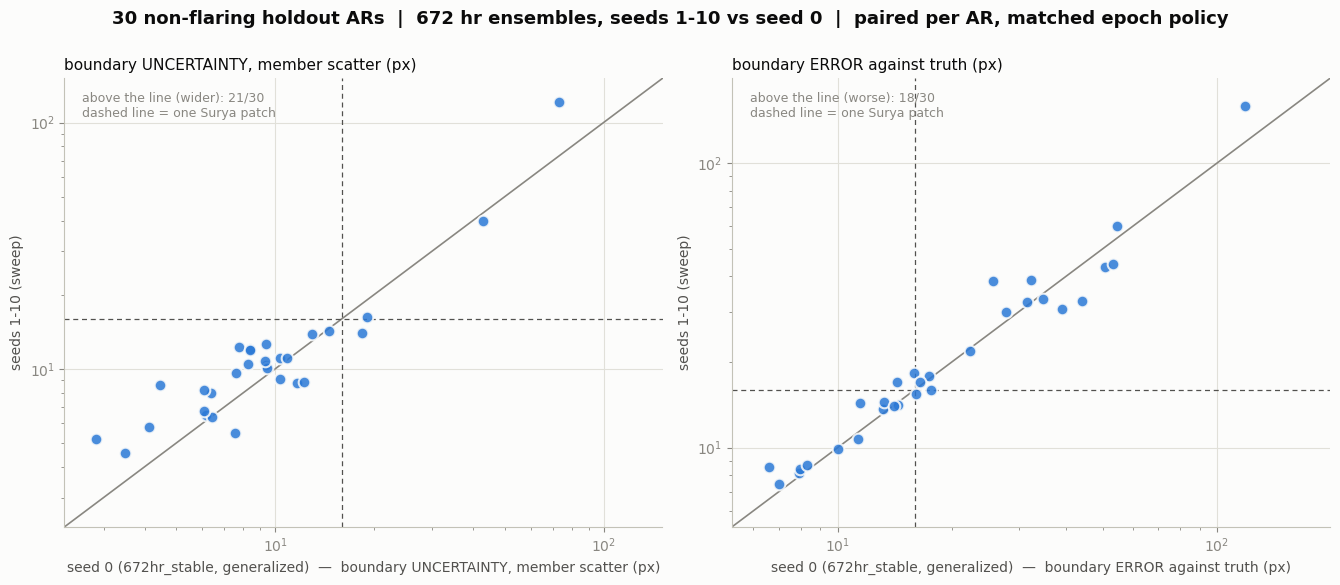

In [8]:
fig, (axl, axr) = plt.subplots(1, 2, figsize=(13.5, 5.8))
fig.suptitle(f"{NF} non-flaring holdout ARs  |  672 hr ensembles, seeds 1-10 vs seed 0  |  "
             "paired per AR, matched epoch policy", fontsize=13, fontweight="bold",
             color=ev.INK, y=1.0)

for ax, (col, name, better) in zip((axl, axr), [
    ("boundary_assd_px", "boundary UNCERTAINTY, member scatter (px)", "wider"),
    ("boundary_error_assd_px", "boundary ERROR against truth (px)", "worse"),
]):
    x = pair[f"{col}_old"].values
    y = pair[col].values
    lim = [min(x.min(), y.min()) * 0.8, max(x.max(), y.max()) * 1.25]
    ax.plot(lim, lim, color=ev.MUTED, lw=1.2, zorder=1)
    ax.scatter(x, y, s=70, color=ev.SERIES_1, alpha=0.85, zorder=3,
               edgecolors=plt.rcParams["figure.facecolor"], linewidths=1.5)
    ax.axvline(PATCH_PX, color=ev.INK_2, lw=0.9, ls=(0, (4, 3)), zorder=2)
    ax.axhline(PATCH_PX, color=ev.INK_2, lw=0.9, ls=(0, (4, 3)), zorder=2)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel(f"seed 0 (672hr_stable, generalized)  —  {name}")
    ax.set_ylabel("seeds 1-10 (sweep)")
    ax.set_title(name, fontsize=11, color=ev.INK, loc="left")
    n_up = int((y > x).sum())
    ax.annotate(f"above the line ({better}): {n_up}/{NF}\ndashed line = one Surya patch",
                (0.03, 0.97), xycoords="axes fraction", va="top", fontsize=9, color=ev.MUTED)
    ev.recessive(ax, grid_axis="both")

plt.tight_layout()
plt.show()

### Is any one member reliably tighter than the others?

**Kendall's $W$** is the concordance of the 30 per-frame member rankings: 1.0 means every frame
orders the members identically, 0 means the orderings are unrelated. A high $W$ says member
identity is a real, transferable property; a low one says per-frame ranking is noise.

On the stabilized 672 hr ensemble at best.pth $W$ collapsed to 0.104 once its broken checkpoints
were gone — the earlier 0.331 had been three members being reliably bad. The question here is
whether *seeding* a member changes its character, which the Spearman at the bottom answers by
pairing each arm's member against its own replicate.

In [9]:
def per_member_table(m):
    t = m.groupby("member").agg(
        epoch=("epoch", "first"), val_iou=("val_iou", "first"),
        assd_mean=("assd_px", "mean"), assd_sd=("assd_px", "std"),
        assd_min=("assd_px", "min"), assd_max=("assd_px", "max"),
        median_px=("median_px", "mean"), hd95=("hd95_px", "mean"), iou=("iou", "mean"),
    ).sort_values("assd_mean")
    wide = m.pivot(index="frame", columns="member", values="assd_px")[list(t.index)]
    ranks = wide.rank(axis=1)
    t["mean_rank"] = ranks.mean()
    t["rank_sd"] = ranks.std(ddof=1)
    return t, wide, ranks


def kendall_w(ranks):
    "k frames rating n members; W = 12 S / (k^2 (n^3 - n))."
    k, n = ranks.shape
    rank_sums = ranks.sum(axis=0).values
    s = ((rank_sums - rank_sums.mean()) ** 2).sum()
    return 12 * s / (k ** 2 * (n ** 3 - n))


for tag, m in [("SWEEP", members), ("BASELINE", base_members)]:
    t, wide, ranks = per_member_table(m)
    out = t[["epoch", "val_iou", "assd_mean", "assd_sd", "assd_min", "assd_max", "median_px",
             "hd95", "iou", "mean_rank", "rank_sd"]].copy()
    out.columns = ["ep", "val IoU", "ASSD px", "sd", "min", "max", "median", "HD95", "IoU",
                   "rank", "rank sd"]
    print(f"=== {tag}  (sorted by mean ASSD about the ensemble boundary)")
    print(out.to_string(float_format=lambda x: f"{x:.3f}"))
    w = kendall_w(ranks)
    chi2 = w * ranks.shape[0] * (ranks.shape[1] - 1)
    print(f"  Kendall's W = {w:.3f}   chi2 = {chi2:.1f} on {ranks.shape[1] - 1} df, "
          f"p = {stats.chi2.sf(chi2, ranks.shape[1] - 1):.2e}")
    print(f"  tightest {t.index[0]} {t.assd_mean.iloc[0]:.2f} px   "
          f"loosest {t.index[-1]} {t.assd_mean.iloc[-1]:.2f} px   "
          f"spread {t.assd_mean.iloc[-1] / t.assd_mean.iloc[0]:.1f}x\n")

# Does a replicate keep its character when reseeded? Pair member-for-member on mean ASSD.
sw = members.groupby("member").assd_px.mean()
bs = base_members.groupby("member").assd_px.mean()
common = sorted(set(sw.index) & set(bs.index))
rho, p_rho = stats.spearmanr(sw[common], bs[common])
print(f"per-member mean ASSD, sweep vs baseline on the same replicate: "
      f"Spearman {rho:+.3f} (p {p_rho:.3f}, n={len(common)})")
print("  high = replicate identity survives reseeding; low = member character is not a property")
print("  of the replicate at all.")

=== SWEEP  (sorted by mean ASSD about the ensemble boundary)
        ep  val IoU  ASSD px     sd   min     max  median    HD95   IoU  rank  rank sd
member                                                                                
boot03   1    0.640    6.425  3.900 2.470  21.404   1.893  27.315 0.688 3.633    2.356
boot02   2    0.583    6.848  4.481 1.910  21.420   1.499  39.172 0.693 4.133    2.270
boot05   2    0.647    8.133  6.990 1.407  27.983   1.183  50.386 0.708 4.167    2.949
boot10   4    0.611    8.321  5.174 2.025  20.902   1.377  44.825 0.720 4.867    3.159
boot07   3    0.647   10.565  8.101 1.748  44.376   1.377  51.443 0.718 6.367    2.385
boot09   2    0.577   11.687 13.694 2.717  78.016   2.214  98.615 0.671 6.100    2.426
boot04   1    0.626   13.053 22.691 2.688 100.561   1.584 164.253 0.707 4.367    2.484
boot06   5    0.608   21.531 54.922 2.120 295.746   1.365 146.583 0.701 5.167    2.666
boot01   3    0.594   26.064 53.379 2.835 294.884   1.410 212.926 0.6

### Variance decomposition — is the member spread an error bar, or is the frame?

A one-way random-effects split of the 300 per-member ASSD values, with frame as the grouping
factor:

$$\sigma^2_{\text{total}} = \sigma^2_{\text{between frames}} + \sigma^2_{\text{within frame (members)}}$$

The **intraclass correlation** $\text{ICC} = \sigma^2_b / (\sigma^2_b + \sigma^2_w)$ is the
fraction of all variation attributable to *which AR you are looking at*. Both 672-sample cohorts
at best.pth landed at 0.19, i.e. 81 % of the variation is members disagreeing — the quantity an
error bar is supposed to be about. Whether seeding changes that split is the question.

In [10]:
def icc_oneway(wide):
    m_, k_ = wide.shape[1], wide.shape[0]
    grand = wide.values.mean()
    frame_means = wide.mean(axis=1)
    ms_between = m_ * ((frame_means - grand) ** 2).sum() / (k_ - 1)
    ms_within = ((wide.values - frame_means.values[:, None]) ** 2).sum() / (k_ * (m_ - 1))
    var_between = max((ms_between - ms_within) / m_, 0.0)
    return dict(grand=grand, ms_between=ms_between, ms_within=ms_within,
                sigma_between=np.sqrt(var_between), sigma_within=np.sqrt(ms_within),
                icc=var_between / (var_between + ms_within))


for tag, m in [("sweep", members), ("baseline", base_members)]:
    _, wide, _ = per_member_table(m)
    d = icc_oneway(wide)
    print(f"=== {tag}  ({wide.shape[0]} frames x {wide.shape[1]} members)")
    print(f"  grand mean ASSD                 {d['grand']:.3f} px")
    print(f"  sigma_between (frame identity)  {d['sigma_between']:.3f} px   "
          f"({100 * d['icc']:.0f} % of variance)")
    print(f"  sigma_within  (member spread)   {d['sigma_within']:.3f} px   "
          f"({100 * (1 - d['icc']):.0f} %)")
    print(f"  ICC                             {d['icc']:.3f}\n")

print("sigma_within is the quantity a bootstrap error bar is made of; comparing it between the")
print("two arms is the variance-component question stated in pixels rather than in IoU.")

=== sweep  (30 frames x 10 members)
  grand mean ASSD                 14.447 px
  sigma_between (frame identity)  18.935 px   (30 % of variance)
  sigma_within  (member spread)   29.054 px   (70 %)
  ICC                             0.298

=== baseline  (30 frames x 10 members)
  grand mean ASSD                 12.255 px
  sigma_between (frame identity)  11.499 px   (20 % of variance)
  sigma_within  (member spread)   22.970 px   (80 %)
  ICC                             0.200

sigma_within is the quantity a bootstrap error bar is made of; comparing it between the
two arms is the variance-component question stated in pixels rather than in IoU.


### Method A vs Method B

$\sigma_r = \sigma_p / |\nabla \bar p|$ (A, the linearized level-set displacement) and the
empirical ASSD (B, the headline) rest on different assumptions. Across the 672-sample cohorts
they did **not** agree — A is a *local* linearization, structurally blind to a detached island or
a whole region the ensemble missed, which is exactly what inflates B. It is reported here for
continuity and because its two assumptions are measured rather than asserted, not as a
cross-check. **B is the headline.**

In [11]:
for tag, f in [("SWEEP", frames), ("BASELINE", base_frames)]:
    c = f[["boundary_assd_px", "sigma_r_mean_px", "sigma_r_median_px", "sigma_r_p90_px",
           "within_patch_range", "seam_bias_ratio"]].copy()
    c["rel_diff_pct"] = 100 * (c.sigma_r_mean_px - c.boundary_assd_px) / c.boundary_assd_px
    print(f"=== {tag}")
    print(f"{'':<34}{'mean +/- sd':>22}   median / range")
    print("-" * 78)
    for label, col, fmt in [
        ("Method B  ASSD (px)", "boundary_assd_px", "{:.2f}"),
        ("Method A  sigma_r mean (px)", "sigma_r_mean_px", "{:.2f}"),
        ("Method A  sigma_r p90 (px)", "sigma_r_p90_px", "{:.1f}"),
        ("A - B, as % of B", "rel_diff_pct", "{:+.1f}"),
        ("within-patch range of p-bar", "within_patch_range", "{:.3f}"),
        ("patch-seam gradient bias (x)", "seam_bias_ratio", "{:.2f}"),
    ]:
        print(f"{label:<34}{describe(c[col], fmt)}")
    r, p_r = stats.pearsonr(c.boundary_assd_px, c.sigma_r_mean_px)
    within20 = int((c.rel_diff_pct.abs() < 20).sum())
    print(f"  A vs B across frames: Pearson r = {r:+.3f} (p {p_r:.3f});  "
          f"{within20}/{len(c)} frames agree within 20 %\n")

=== SWEEP
                                             mean +/- sd   median / range
------------------------------------------------------------------------------
Method B  ASSD (px)               14.45 +/- 21.05   median 10.21   [4.55, 120.93]
Method A  sigma_r mean (px)       7.02 +/- 2.53   median 6.43   [3.47, 13.80]
Method A  sigma_r p90 (px)        15.1 +/- 6.1   median 13.8   [6.7, 29.0]
A - B, as % of B                  -27.1 +/- +29.3   median -29.5   [-97.1, +21.3]
within-patch range of p-bar       0.625 +/- 0.034   median 0.633   [0.527, 0.674]
patch-seam gradient bias (x)      1.54 +/- 0.05   median 1.54   [1.42, 1.64]
  A vs B across frames: Pearson r = -0.218 (p 0.247);  10/30 frames agree within 20 %

=== BASELINE
                                             mean +/- sd   median / range
------------------------------------------------------------------------------
Method B  ASSD (px)               12.25 +/- 13.60   median 8.86   [2.85, 73.18]
Method A  sigma_r mean (px) 

### The whole distribution, not just its mean

Every boundary-to-boundary distance from all 30 frames, pooled. Read any point as *"this fraction
of boundary pixels lie within x px"*. Members in grey, ground truth in orange — the gap between
them **is** the gap between what the ensemble thinks it knows and how wrong it is.

Built from the per-frame histograms the analysis script accumulated (0.25 px bins out to 64 px,
log-spaced beyond), so this is the exact pooled distribution over ~$10^8$ distances rather than a
sample of it. One patch is an exact bin edge, so the "within one patch" figures are read off a
boundary rather than interpolated.

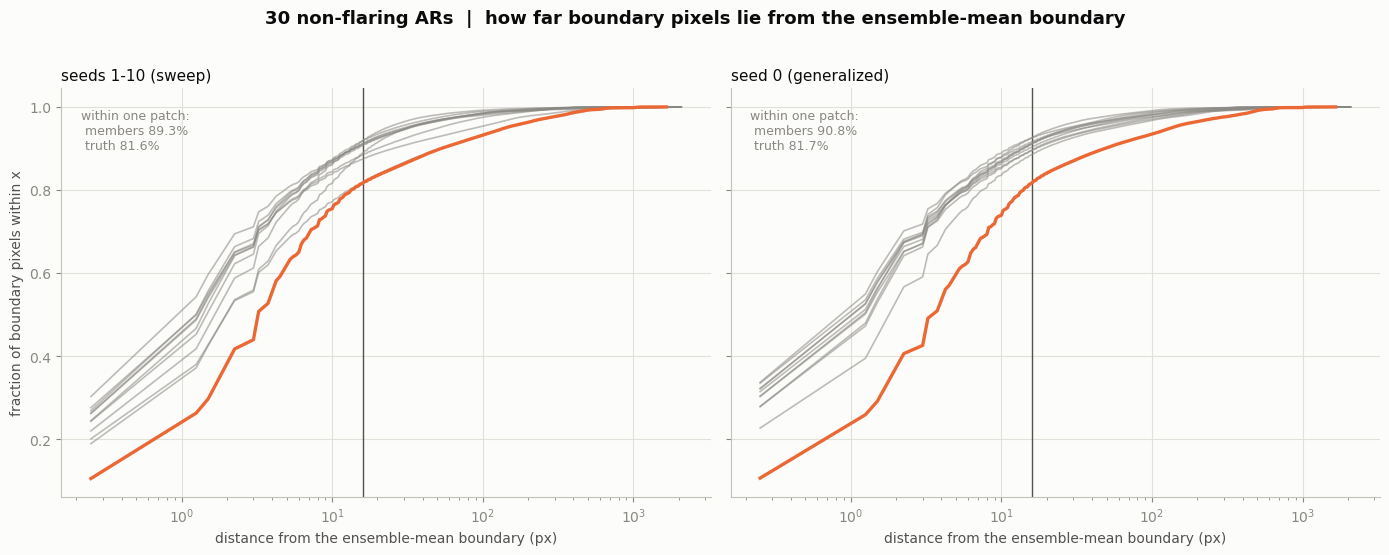

sweep     pooled over 17.7 M member distances and 1.17 M truth distances;  within one patch: members 89.3%, truth 81.6%
baseline  pooled over 18.6 M member distances and 1.36 M truth distances;  within one patch: members 90.8%, truth 81.7%


In [12]:
def pooled_ecdf(df):
    "Summed counts -> (upper bin edge, cumulative fraction, total)."
    g = df.groupby("bin_hi", as_index=False)["count"].sum().sort_values("bin_hi")
    total = g["count"].sum()
    return g.bin_hi.values, np.cumsum(g["count"].values) / total, total


fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True)
fig.suptitle(f"{NF} non-flaring ARs  |  how far boundary pixels lie from the ensemble-mean "
             "boundary", fontsize=13, fontweight="bold", color=ev.INK, y=1.02)

for ax, (tag, dh) in zip(axes, [("seeds 1-10 (sweep)", dhist),
                                ("seed 0 (generalized)", base_dhist)]):
    is_truth = dh.series == "ground truth"
    for member in sorted(dh.loc[~is_truth, "series"].unique()):
        x, y, _ = pooled_ecdf(dh[dh.series == member])
        ax.plot(x, y, color=ev.MUTED, lw=1.2, alpha=0.55, zorder=2)
    xt, yt, n_t = pooled_ecdf(dh[is_truth])
    ax.plot(xt, yt, color=ev.SERIES_2, lw=2.4, zorder=4)
    ax.axvline(PATCH_PX, color=ev.INK_2, lw=1.0, zorder=1)
    ax.set_xscale("log")
    ax.set_xlabel("distance from the ensemble-mean boundary (px)")
    ax.set_title(tag, fontsize=11, color=ev.INK, loc="left")
    frac_m = np.interp(PATCH_PX, *pooled_ecdf(dh[~is_truth])[:2])
    frac_t = np.interp(PATCH_PX, xt, yt)
    ax.annotate(f"within one patch:\n members {100 * frac_m:.1f}%\n truth {100 * frac_t:.1f}%",
                (0.03, 0.95), xycoords="axes fraction", va="top", fontsize=9, color=ev.MUTED)
    ev.recessive(ax, grid_axis="both")
axes[0].set_ylabel("fraction of boundary pixels within x")
axes[0].annotate("one Surya patch", (PATCH_PX, 0.04), xytext=(7, 0),
                 textcoords="offset points", fontsize=8.5, color=ev.INK_2)
plt.tight_layout()
plt.show()

for tag, dh in [("sweep", dhist), ("baseline", base_dhist)]:
    is_truth = dh.series == "ground truth"
    xm, ym, nm = pooled_ecdf(dh[~is_truth])
    xt, yt, nt = pooled_ecdf(dh[is_truth])
    print(f"{tag:9s} pooled over {nm / 1e6:.1f} M member distances and {nt / 1e6:.2f} M truth "
          f"distances;  within one patch: members {100 * np.interp(PATCH_PX, xm, ym):.1f}%, "
          f"truth {100 * np.interp(PATCH_PX, xt, yt):.1f}%")

### Does the ratio track mask density?

The obvious confounder: if error-over-uncertainty simply grows with how much AR is in the frame,
then any difference between the arms could be a density artifact. It is not — the cohort is
identical in both arms by construction — but the null is worth re-checking at this epoch policy,
because it is the one that licenses reading the ratio as a property of the *ensemble*.

Spearman rather than Pearson: the question is monotonicity, and both quantities are long-tailed.

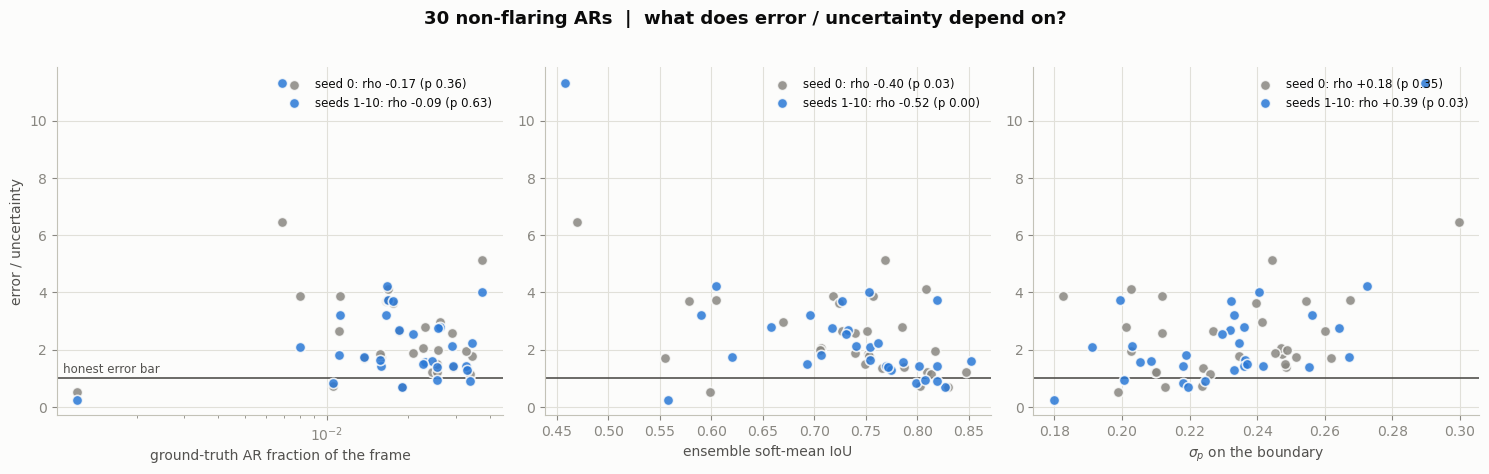

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
fig.suptitle(f"{NF} non-flaring ARs  |  what does error / uncertainty depend on?",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.02)

for ax, (col, xlabel, logx) in zip(axes, [
    ("truth_frac", "ground-truth AR fraction of the frame", True),
    ("soft_iou", "ensemble soft-mean IoU", False),
    ("boundary_sigma_prob", r"$\sigma_p$ on the boundary", False),
]):
    for f, color, tag in [(base_frames, ev.MUTED, "seed 0"),
                          (frames, ev.SERIES_1, "seeds 1-10")]:
        rho, p_s = stats.spearmanr(f[col], f.boundary_error_over_uncertainty)
        ax.scatter(f[col], f.boundary_error_over_uncertainty, s=55, color=color, alpha=0.85,
                   zorder=3, edgecolors=plt.rcParams["figure.facecolor"], linewidths=1.2,
                   label=f"{tag}: rho {rho:+.2f} (p {p_s:.2f})")
    ax.axhline(1.0, color=ev.INK_2, lw=1.2, zorder=1)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.legend(frameon=False, fontsize=8.5, loc="upper right")
    ev.recessive(ax, grid_axis="both")
axes[0].set_ylabel("error / uncertainty")
axes[0].annotate("honest error bar", (axes[0].get_xlim()[0], 1.0), xytext=(4, 4),
                 textcoords="offset points", fontsize=8.5, color=ev.INK_2)
plt.tight_layout()
plt.show()

## 3. §7 — Calibration, over 30 frames

Bin pixels by $\bar p$ and compare against the observed ground-truth frequency. On the diagonal
is perfect; **below is over-confident, above is under-confident**.

**A different axis from §2, and the two must not be merged.** §2 asked whether the member spread
is an honest error bar on the boundary's *position*. This asks whether $\bar p$ is an honest
frequency for a pixel's *class*.

**Restricted to pixels where at least one member fired.** The $k = 0$ population is ~95 % of each
frame and would set the curve's left end on its own; its own AR content is reported separately,
because that is where the ensemble's misses hide.

The pooled curve sums the raw per-frame bin accumulators ($n$, $n_{\text{true}}$,
$\sum \bar p$), so it is the exact curve over all 30 frames' pixels — not an average of 30
per-frame curves, which would weight a sparse frame the same as a dense one.

**This is the section most affected by the epoch policy, and the reason the baseline had to be
re-run.** Both arms sit at or near their validation-loss floor by construction, so these numbers
should be *better* calibrated than the best.pth `672hr_stable` figures (Brier 0.1168, bias
+0.0021, ECE 0.0585) — and are not comparable to them.

In [14]:
def pool(b):
    p = b.groupby(["bin_lo", "bin_hi"], as_index=False)[["n", "n_true", "sum_p"]].sum()
    p["mean_p"] = p.sum_p / p.n
    p["observed"] = p.n_true / p.n
    p["reliable"] = p.n >= MIN_N
    return p


def summarize(p, f, tag):
    n_tot = int(p.n.sum())
    mean_p = float(p.sum_p.sum() / n_tot)
    observed = float(p.n_true.sum() / n_tot)
    ok = p.reliable & p.n.gt(0)
    w = p.n[ok] / p.n[ok].sum()
    ece = float((w * (p.observed[ok] - p.mean_p[ok]).abs()).sum())
    # Exact pooled Brier: the n-weighted mean of the per-frame Briers.
    brier = float((f.brier * f.n_binned).sum() / f.n_binned.sum())
    print(f"{tag:9s} pixels {n_tot / 1e6:7.2f} M   mean p-bar {mean_p:.4f}   "
          f"observed {observed:.4f}   bias {mean_p - observed:+.4f}   "
          f"Brier {brier:.4f}   ECE {ece:.4f}")
    return dict(pooled=p, mean_p=mean_p, observed=observed, ece=ece, brier=brier)


sw_cal = summarize(pool(bins), frames, "sweep")
bs_cal = summarize(pool(base_bins), base_frames, "baseline")

print("\nreliability table, sweep (pooled over all 30 frames):")
p = sw_cal["pooled"]
show = p.assign(bin=lambda d: d.bin_lo.map("{:.1f}".format) + "-" + d.bin_hi.map("{:.1f}".format))
print(show[["bin", "n", "n_true", "mean_p", "observed", "reliable"]].to_string(
    index=False, float_format=lambda x: f"{x:.4f}"))

print("\nthe k = 0 population, where the misses hide:")
for tag, f in [("sweep", frames), ("baseline", base_frames)]:
    print(f"  {tag:9s} {100 * f.quiet_frac.mean():.1f} % of each frame has no member firing, "
          f"and it still holds {100 * f.missed_ar_frac.mean():.1f} +/- "
          f"{100 * f.missed_ar_frac.std(ddof=1):.1f} % of that frame's true AR")

sweep     pixels   13.93 M   mean p-bar 0.7126   observed 0.7117   bias +0.0009   Brier 0.1164   ECE 0.0069
baseline  pixels   13.32 M   mean p-bar 0.7154   observed 0.7368   bias -0.0213   Brier 0.1147   ECE 0.0214

reliability table, sweep (pooled over all 30 frames):
    bin       n  n_true  mean_p  observed  reliable
0.0-0.1  212780   13399  0.0823    0.0630      True
0.1-0.2  818706  112108  0.1522    0.1369      True
0.2-0.3 1006652  267196  0.2508    0.2654      True
0.3-0.4  988237  366469  0.3491    0.3708      True
0.4-0.5  886589  403585  0.4493    0.4552      True
0.5-0.6  870150  462721  0.5499    0.5318      True
0.6-0.7  849113  546759  0.6499    0.6439      True
0.7-0.8  929059  687752  0.7518    0.7403      True
0.8-0.9 1243507 1059551  0.8531    0.8521      True
0.9-1.0 6124980 5994040  0.9794    0.9786      True

the k = 0 population, where the misses hide:
  sweep     97.2 % of each frame has no member firing, and it still holds 5.3 +/- 2.0 % of that frame's true AR

### Is the direction of the miscalibration consistent, and did seeding move it?

The pooled curve can hide cancelling frames. If the sign of the bias is the same on nearly every
AR, the miscalibration is a property of the ensemble; if mixed, the pooled number is an average
of two different behaviours and no single threshold correction applies.

In [15]:
print(f"{'':<34}{'mean +/- sd':>22}   median / range")
print("-" * 78)
for tag, f in [("SWEEP", frames), ("BASELINE", base_frames)]:
    print(f"=== {tag}")
    for label, col, fmt in [
        ("Brier (per frame)", "brier", "{:.4f}"),
        ("bias (p-bar - observed)", "bias", "{:+.4f}"),
        ("ECE", "ece", "{:.4f}"),
        ("mean p-bar where >=1 fired", "mean_p", "{:.4f}"),
    ]:
        print(f"{label:<34}{describe(f[col], fmt)}")
    n_under = int((f.bias < 0).sum())
    _, p_w = stats.wilcoxon(f.bias)
    print(f"  under-confident (bias < 0): {n_under}/{NF}   over-confident: {NF - n_under}/{NF}   "
          f"Wilcoxon vs 0: p = {p_w:.2e}  -> sign is "
          f"{'CONSISTENT' if p_w < 0.05 else 'not consistent'}\n")

print(f"{'':<30}{'sweep':>10}{'seed 0':>10}{'mean d':>11}{'median d':>11}"
      f"{'n up':>8}{'Wilcoxon':>11}")
print("-" * 92)
for label, col, fmt in [
    ("Brier", "brier", "{:.4f}"),
    ("bias (p-bar - observed)", "bias", "{:+.4f}"),
    ("|bias|", "abs_bias", "{:.4f}"),
    ("ECE", "ece", "{:.4f}"),
    ("mean p-bar", "mean_p", "{:.4f}"),
    ("missed AR fraction at k=0", "missed_ar_frac", "{:.4f}"),
]:
    if col == "abs_bias":
        pair["abs_bias"] = pair.bias.abs()
        pair["abs_bias_old"] = pair.bias_old.abs()
    print(f"{label:<30}{paired(col, fmt)}")
print("\n* = p < 0.05;  'n up' counts ARs where the sweep's value exceeds the baseline's")

                                             mean +/- sd   median / range
------------------------------------------------------------------------------
=== SWEEP
Brier (per frame)                 0.1211 +/- 0.0317   median 0.1149   [0.0734, 0.1990]
bias (p-bar - observed)           +0.0102 +/- +0.0595   median +0.0025   [-0.0548, +0.2582]
ECE                               0.0555 +/- 0.0409   median 0.0468   [0.0233, 0.2582]
mean p-bar where >=1 fired        0.7061 +/- 0.0707   median 0.7161   [0.4803, 0.8126]
  under-confident (bias < 0): 15/30   over-confident: 15/30   Wilcoxon vs 0: p = 6.85e-01  -> sign is not consistent

=== BASELINE
Brier (per frame)                 0.1198 +/- 0.0321   median 0.1113   [0.0780, 0.1905]
bias (p-bar - observed)           -0.0124 +/- +0.0590   median -0.0203   [-0.0752, +0.2404]
ECE                               0.0583 +/- 0.0390   median 0.0489   [0.0272, 0.2409]
mean p-bar where >=1 fired        0.7083 +/- 0.0775   median 0.7090   [0.4415, 0.8118]


### The pooled reliability curve

The 30 per-frame curves sit behind the pooled one in grey, so the spread is visible rather than
averaged away. Bin counts are in the lower panel on a log scale, **not** a second y-axis: a bin
holding $10^3$ pixels and one holding $10^7$ must not be drawn as equals.

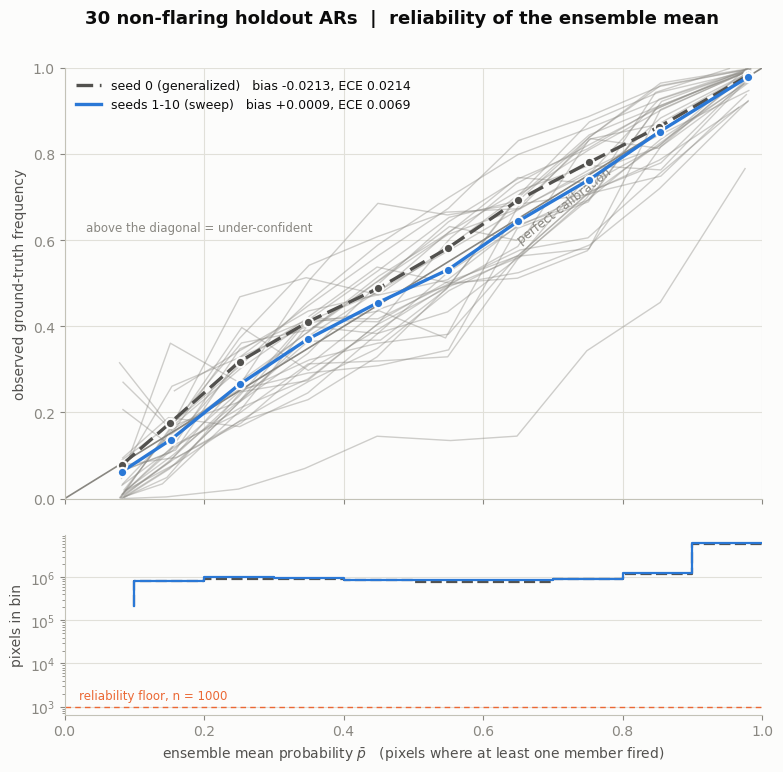

In [16]:
fig, (ax, axc) = plt.subplots(2, 1, figsize=(9, 8.4), sharex=True,
                              gridspec_kw={"height_ratios": [2.4, 1], "hspace": 0.12})
fig.suptitle(f"{NF} non-flaring holdout ARs  |  reliability of the ensemble mean",
             fontsize=13, fontweight="bold", color=ev.INK, y=0.95)

ax.plot([0, 1], [0, 1], color=ev.MUTED, lw=1.2, zorder=2)
ax.annotate("perfect calibration", (0.72, 0.72), xytext=(0, -14), textcoords="offset points",
            ha="center", fontsize=9, color=ev.MUTED, rotation=38, rotation_mode="anchor")

for frame_id, g in bins.groupby("frame"):
    g = g[g.n >= MIN_N]
    if len(g) > 1:
        ax.plot(g.sum_p / g.n, g.n_true / g.n, color=ev.MUTED, lw=1.0, alpha=0.4, zorder=3)

for cal, color, tag, ls in [(bs_cal, ev.INK_2, "seed 0 (generalized)", (0, (5, 2))),
                            (sw_cal, ev.SERIES_1, "seeds 1-10 (sweep)", "solid")]:
    p = cal["pooled"]
    ok = p.reliable & p.n.gt(0)
    ax.plot(p.mean_p[ok], p.observed[ok], color=color, lw=2.4, ls=ls, zorder=5,
            label=f"{tag}   bias {cal['mean_p'] - cal['observed']:+.4f}, ECE {cal['ece']:.4f}")
    ax.scatter(p.mean_p[ok], p.observed[ok], s=45, color=color, zorder=6,
               edgecolors=plt.rcParams["figure.facecolor"], linewidths=1.5)
    axc.step(p.bin_hi, p.n, where="pre", color=color, lw=1.6, ls=ls)

ax.set_ylabel(r"observed ground-truth frequency")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.annotate("above the diagonal = under-confident", (0.03, 0.62), xycoords="axes fraction",
            fontsize=8.5, color=ev.MUTED)
ev.recessive(ax, grid_axis="both")

axc.set_yscale("log")
axc.set_xlabel(r"ensemble mean probability $\bar p$   (pixels where at least one member fired)")
axc.set_ylabel("pixels in bin")
axc.axhline(MIN_N, color=ev.SERIES_2, lw=1.0, ls=(0, (4, 3)))
axc.annotate(f"reliability floor, n = {MIN_N}", (0.02, MIN_N), xytext=(0, 5),
             textcoords="offset points", fontsize=8.5, color=ev.SERIES_2)
ev.recessive(axc, grid_axis="y")
plt.show()

## 4. Three exemplars

The aggregate needs something concrete under it. The AR with the **lowest**, the **median** and
the **highest** error-over-uncertainty in the sweep, each with the $\sigma_r$ map on its own most
contested window.

$\sigma_r$ is recomputed here from the cached $\bar p$ and $\sigma_p$ rather than stored: it
costs a second and would have added 67 MB per frame to the cache. Drawn only on the transition
band $0.1 < \bar p < 0.9$ — outside it, $\sigma_p / |\nabla \bar p|$ divides a near-zero
numerator by a near-zero denominator, which is numerical noise with no boundary to be the
uncertainty *of*. Values are clipped at one patch rather than rescaled, so the colour means the
same thing on all three panels.

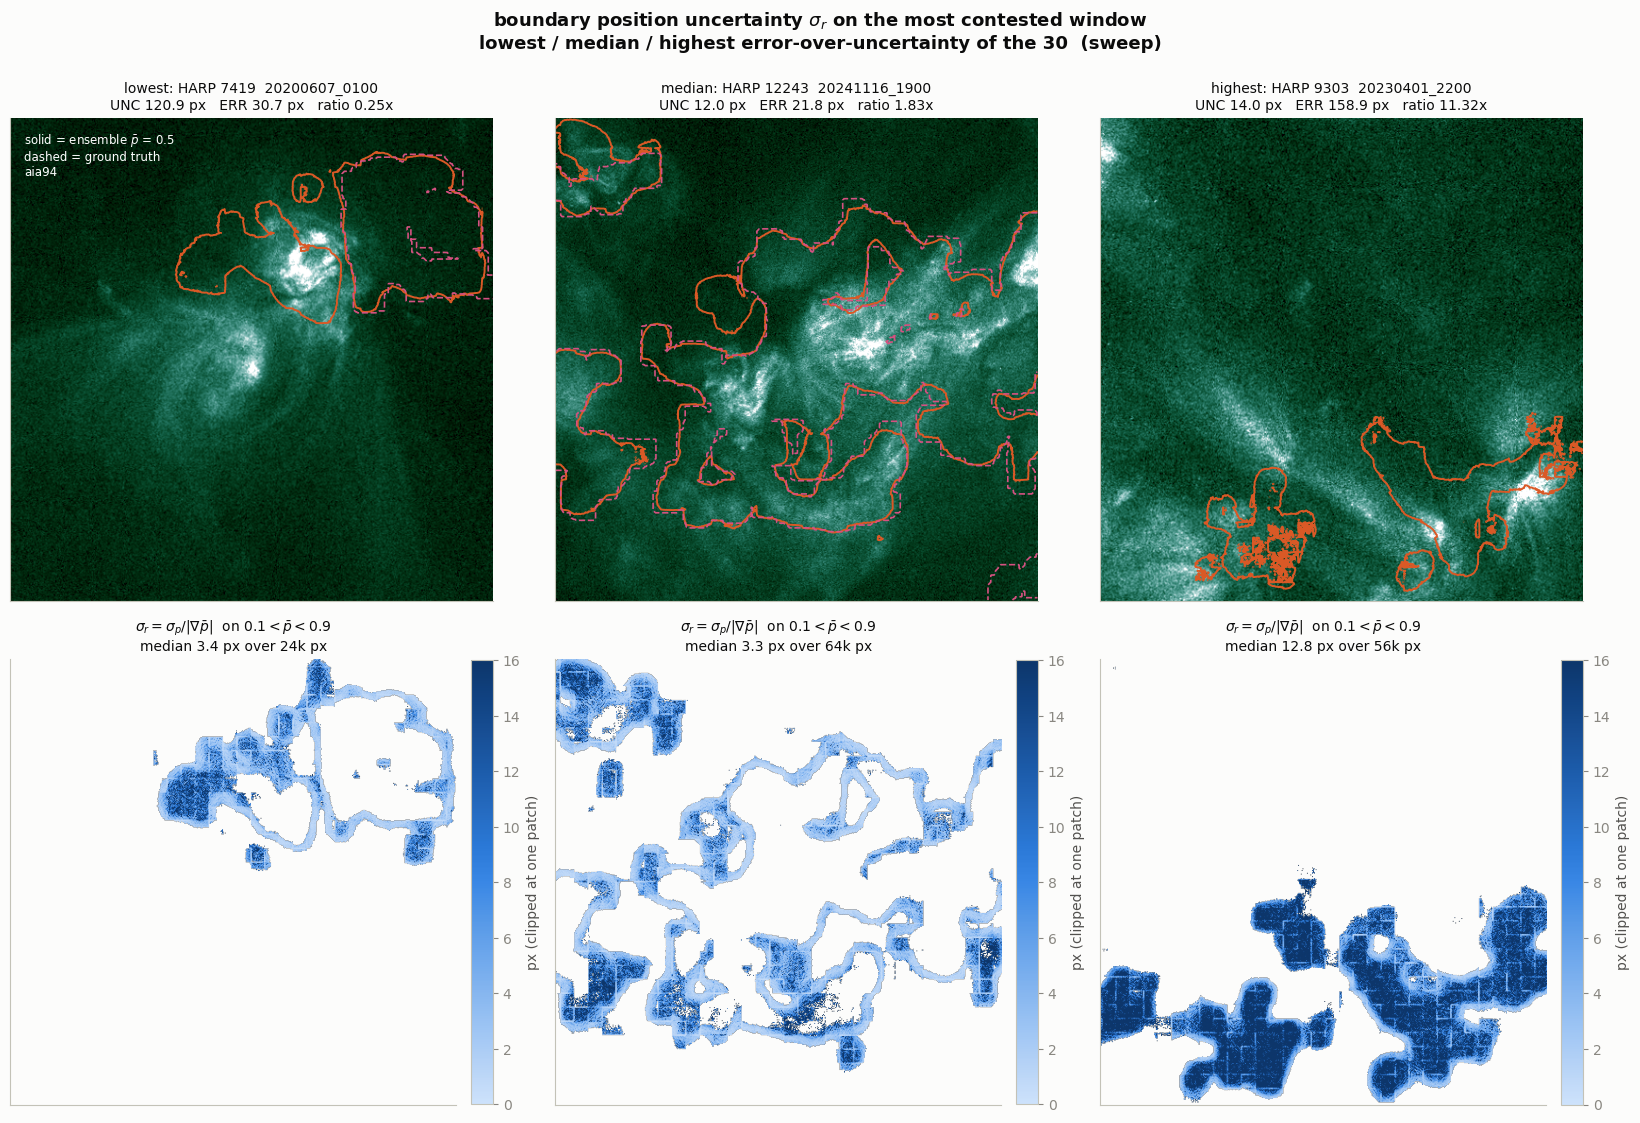

In [17]:
ordered = frames.sort_values("boundary_error_over_uncertainty").reset_index(drop=True)
picks = [("lowest", ordered.iloc[0]), ("median", ordered.iloc[NF // 2]),
         ("highest", ordered.iloc[-1])]


def load_channel(frame_dir, channel):
    "One channel in display units: undoes the standardization only, as infer_file does."
    with xr.open_dataset(os.path.join(frame_dir, "channels.nc"), engine="h5netcdf") as ds:
        normalized = ds[channel].values.astype(np.float32)
    s = scalers[channel]
    return normalized * (s["std"] + s["epsilon"]) + s["mean"]


fig, axes = plt.subplots(2, 3, figsize=(16.5, 11.4))
fig.suptitle(r"boundary position uncertainty $\sigma_r$ on the most contested window"
             "\nlowest / median / highest error-over-uncertainty of the 30  (sweep)",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.0)

for col, (tag, row) in enumerate(picks):
    frame_dir = os.path.join(SWEEP_ROOT, row.frame)
    y0, x0, y1, x1 = int(row.win_y0), int(row.win_x0), int(row.win_y1), int(row.win_x1)
    with xr.open_dataset(os.path.join(frame_dir, "ensemble_mean.nc"), engine="h5netcdf") as ds:
        p_mean = ds.ar_probability_mean.values[y0:y1, x0:x1].astype(np.float32)
        p_sd = ds.ar_probability_sd.values[y0:y1, x0:x1].astype(np.float32)
        truth = ds.ground_truth.values[y0:y1, x0:x1].astype(np.float32)

    img = load_channel(frame_dir, CHANNEL)[y0:y1, x0:x1]
    vmin, vmax = ev.channel_clim(CHANNEL, img)
    ax = axes[0, col]
    ax.imshow(img, cmap=ev.channel_cmap(CHANNEL), vmin=vmin, vmax=vmax, origin="lower")
    ax.contour(p_mean, levels=[0.5], colors=[ev.CONTOUR[0.5]], linewidths=1.4)
    ax.contour(truth, levels=[0.5], colors=[ev.MASK_FILL], linewidths=1.2, linestyles="dashed")
    ax.set_title(f"{tag}: HARP {int(row.harpnum)}  {row.frame}\n"
                 f"UNC {row.boundary_assd_px:.1f} px   ERR {row.boundary_error_assd_px:.1f} px   "
                 f"ratio {row.boundary_error_over_uncertainty:.2f}x",
                 fontsize=10, color=ev.INK)
    ax.set_xticks([]); ax.set_yticks([])

    gy, gx = np.gradient(p_mean)
    grad = np.hypot(gy, gx)
    band = (p_mean > 0.1) & (p_mean < 0.9) & (grad > 0)
    sigma_r = np.full_like(p_mean, np.nan)
    sigma_r[band] = np.clip(p_sd[band] / grad[band], 0, PATCH_PX)
    ax = axes[1, col]
    im = ax.imshow(sigma_r, cmap=ev.SEQ, vmin=0, vmax=PATCH_PX, origin="lower")
    ax.set_title(r"$\sigma_r = \sigma_p / |\nabla \bar p|$  on $0.1 < \bar p < 0.9$"
                 f"\nmedian {np.nanmedian(sigma_r):.1f} px over "
                 f"{int(band.sum()) / 1e3:.0f}k px", fontsize=10, color=ev.INK)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="px (clipped at one patch)")

axes[0, 0].annotate(f"solid = ensemble $\\bar p$ = 0.5\ndashed = ground truth\n{CHANNEL}",
                    (0.03, 0.97), xycoords="axes fraction", va="top", fontsize=8.5,
                    color="white")
plt.tight_layout()
plt.show()

## 5. What this cohort says

In [18]:
d_unc = pair.boundary_assd_px - pair.boundary_assd_px_old
d_err = pair.boundary_error_assd_px - pair.boundary_error_assd_px_old
d_ratio = pair.boundary_error_over_uncertainty - pair.boundary_error_over_uncertainty_old
_, p_unc = stats.wilcoxon(d_unc)
_, p_err = stats.wilcoxon(d_err)
_, p_ratio = stats.wilcoxon(d_ratio)

sw_w = icc_oneway(per_member_table(members)[1])
bs_w = icc_oneway(per_member_table(base_members)[1])

print("THE SEED QUESTION, in one block")
print("-" * 86)
print(f"  boundary UNCERTAINTY   sweep {frames.boundary_assd_px.mean():6.2f} px   "
      f"seed 0 {base_frames.boundary_assd_px.mean():6.2f} px   "
      f"paired d {d_unc.mean():+.2f} px (median {d_unc.median():+.2f}), p {p_unc:.3f}")
print(f"  boundary ERROR         sweep {frames.boundary_error_assd_px.mean():6.2f} px   "
      f"seed 0 {base_frames.boundary_error_assd_px.mean():6.2f} px   "
      f"paired d {d_err.mean():+.2f} px (median {d_err.median():+.2f}), p {p_err:.3f}")
print(f"  ERROR / UNCERTAINTY    sweep {frames.boundary_error_over_uncertainty.mean():6.2f}x   "
      f"seed 0 {base_frames.boundary_error_over_uncertainty.mean():6.2f}x   "
      f"paired d {d_ratio.mean():+.2f}, p {p_ratio:.3f}")
print(f"  member spread sigma_w  sweep {sw_w['sigma_within']:6.2f} px   "
      f"seed 0 {bs_w['sigma_within']:6.2f} px      "
      f"ICC {sw_w['icc']:.3f} vs {bs_w['icc']:.3f}")
print(f"  calibration            sweep Brier {sw_cal['brier']:.4f} bias "
      f"{sw_cal['mean_p'] - sw_cal['observed']:+.4f} ECE {sw_cal['ece']:.4f}   "
      f"seed 0 Brier {bs_cal['brier']:.4f} bias "
      f"{bs_cal['mean_p'] - bs_cal['observed']:+.4f} ECE {bs_cal['ece']:.4f}")
print(f"  validation IoU         sweep "
      f"{sel[sel.arm == 'sweep'].iou_chosen.mean():.4f} +/- "
      f"{sel[sel.arm == 'sweep'].iou_chosen.std(ddof=1):.4f}   seed 0 "
      f"{sel[sel.arm == 'baseline'].iou_chosen.mean():.4f} +/- "
      f"{sel[sel.arm == 'baseline'].iou_chosen.std(ddof=1):.4f}")
print(f"  per-member d ASSD      matched {pm.loc[pm.matched, 'd_assd'].mean():+.2f} px   "
      f"short {pm.loc[~pm.matched, 'd_assd'].mean():+.2f} px   "
      f"(4 vs 6 of 10 replicates; the budget confound, split)")
print()
print(f"  Both arms still have error well above uncertainty: "
      f"{int((frames.boundary_error_over_uncertainty > 1).sum())}/{NF} and "
      f"{int((base_frames.boundary_error_over_uncertainty > 1).sum())}/{NF} frames above 1.0x.")
print("  Whatever seeding does or does not add, it does not close that gap -- the gap is bias,")
print("  and all 20 arms share the frozen surya.366m.v1.pt backbone.")
print()
print("  CAVEAT, restated because it bounds every line above: 6 of the 10 sweep members trained")
print("  4-5 epochs against the baseline's 6, so this differences seed AND an unevenly")
print("  distributed budget bias. Unlike the 168 hr pair, LR SCHEDULE is NOT a confound here --")
print("  both arms ran warmup 70 + cosine + clip 1.0. A null result is the strong reading; a")
print("  difference cannot be attributed to the seed alone. The matched/short split above is the")
print("  closest this cohort gets to separating them.")

THE SEED QUESTION, in one block
--------------------------------------------------------------------------------------
  boundary UNCERTAINTY   sweep  14.45 px   seed 0  12.25 px   paired d +2.19 px (median +0.97), p 0.080
  boundary ERROR         sweep  26.64 px   seed 0  25.26 px   paired d +1.38 px (median +0.45), p 0.289
  ERROR / UNCERTAINTY    sweep   2.37x   seed 0   2.43x   paired d -0.06, p 0.109
  member spread sigma_w  sweep  29.05 px   seed 0  22.97 px      ICC 0.298 vs 0.200
  calibration            sweep Brier 0.1164 bias +0.0009 ECE 0.0069   seed 0 Brier 0.1147 bias -0.0213 ECE 0.0214
  validation IoU         sweep 0.6116 +/- 0.0272   seed 0 0.6166 +/- 0.0242
  per-member d ASSD      matched +2.07 px   short +2.27 px   (4 vs 6 of 10 replicates; the budget confound, split)

  Both arms still have error well above uncertainty: 25/30 and 27/30 frames above 1.0x.
  Whatever seeding does or does not add, it does not close that gap -- the gap is bias,
  and all 20 arms share t

### Reading it

**The error bar did widen, but weakly, and the significant part of it is the tail rather than
the boundary.** UNC goes 12.25 → 14.45 px, a paired +2.19 px on 21/30 ARs — and that is
**p = 0.080, not significant**. What *is* significant is the tail: member-ASSD sd +2.08 px
(p = 0.016) and member HD95 +28.5 px (p = 0.018). Taking the median instead of the mean shrinks
the widening by **3.3×**, from +2.19 to +0.66 px on per-member medians, and the pooled ECDF says
the *core* is if anything marginally tighter in the sweep: 89.3 % of member boundary pixels
within one Surya patch against the baseline's 90.8 %. So seeding does not uniformly inflate the
spread — it occasionally produces a badly-placed member. `boot08`'s +21.9 px is one frame,
`20200607_0100` (HARP 7419, `truth_frac` 0.00121, the cohort minimum), at 390.7 px against
`boot08`'s own 14.9 px median.

**The budget confound does not explain it.** +2.07 px on the four budget-matched replicates
against +2.27 px on the six short ones — the two subsets are indistinguishable, so this is not
an artifact of the members that trained 4–5 epochs. Per-member d IoU is ≈ 0 either way
(−0.0031 matched, +0.0014 short), the holdout analogue of the validation-level −0.0041 / p 0.26.
That retires the one thing `CONFOUND_NOTES` warned would make the paired read unusable.

**It does not make the error bar honest, which is the question that matters.** The error did not
move (+1.38 px, p = 0.289) and the ratio is unchanged (2.37× vs 2.43×, p = 0.109), with 25/30
and 27/30 ARs still above 1.0×. Both arms remain ~2.4× under-dispersed. Adding the
optimization-path component does not close a gap that is bias, and all 20 arms share the frozen
`surya.366m.v1.pt` backbone.

**Where seeding genuinely helps is calibration — and the direction is the opposite of what the
per-AR bias shift suggests at first glance.** The paired shift is +0.0226 on all 30 ARs, but
read what it moves *from* and *to*: the baseline is **systematically under-confident** (bias
−0.0124, 22/30 ARs negative, sign test p = 0.016), while the sweep has **no consistent sign at
all** (15/30 vs 15/30, p = 0.685). Pooled over 13.9 M pixels the bias goes −0.0213 → **+0.0009**
and pooled ECE **0.0214 → 0.0069, a 3× improvement**. Seeding removes a systematic
under-confidence rather than introducing over-confidence. Brier is unmoved (p = 0.309), so this
is a bias correction, not a sharpness gain.

**The mechanism is a small, uniform operating-point shift.** The seeded ensemble fires slightly
more: predicted fraction +0.0008 on **30/30** ARs (p = 1.9e−09), recall +0.0195 on 29/30
(p = 5.6e−09), precision −0.0213 on 2/30 (p = 9.3e−09), and the AR it misses in the
no-member-fired region falls 6.30 % → 5.35 % on 26/30 (p = 1.0e−06). Precision and recall trade
off almost exactly, so soft IoU is statistically identical (0.7301 vs 0.7296, p = 1.00). Firing
a little more is what both widens the spread and removes the under-confidence.

**One structural change worth noting.** ICC rises 0.200 → 0.298 and Kendall's *W* 0.103 → 0.287,
so in the seeded arm member identity is a *more* transferable property — largely because
`boot08` is reliably bad (5.0× spread tightest-to-loosest, against the baseline's 3.2×). The
baseline's ICC of 0.200 reproduces the 0.19–0.20 both earlier 672-sample cohorts landed at,
which is a useful consistency check on this pipeline. Replicate character partly survives
reseeding: Spearman +0.600 (p = 0.067) between the two arms' per-member mean ASSD.

**Bottom line.** Published bootstrap error bars at this budget are missing an
optimization-path component, but a small one: ~9 % on robust statistics, ~18 % on means, and not
significant at the frame level. Because the error is unchanged, adding it does not improve the
error bar's honesty — the 2.4× under-dispersion is bias, not missing variance. The real payoff
of seeding is calibration: a 3× better pooled ECE and the removal of a systematic
under-confidence, at no IoU cost.

**Caveat that still bounds all of the above.** Six of the ten sweep members trained 4–5 epochs
against the baseline's 6, so this differences seed *and* an unevenly distributed budget bias.
Unlike the 168 hr pair, LR schedule is **not** a confound — both arms ran warmup 70 + cosine +
clip 1.0. The matched/short split is the strongest available evidence that the budget is not
driving the result, but it is a 4-vs-6 split of ten replicates, not a designed experiment.
Retraining the remaining six at 6 epochs is what would retire the note. Note also that the
sweep's `boot07` pick sits 8.43 σ below its own peak IoU, so one of ten members is a checkpoint
that is neither calibrated nor IoU-competitive.